# EDA

In [1]:
# library import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# importing data loaders
import data_loaders as dl

In [2]:
# initializing data loader
loader = dl.DataLoader()

### Day ahead prices EDA

In [3]:
# Loading the data
dap = loader.day_ahead_price_data.copy()

In [4]:
print('=== Day Ahead Price Data ========')
print(f'Shape: {dap.shape}')
print(f'Columns: {dap.columns}')
print(f'Null values: {dap.isnull().sum().sum()}')
print(f'Duplicated values: {dap.duplicated().sum()}')
print(f'Data types: {dap.dtypes}')
print(f'Statistics: {dap.describe()}')
print('=================================')

=== Day Ahead Price Data ========
Shape: (103062, 2)
Columns: Index(['date', 'Day-ahead price (EUR/MWh)'], dtype='str')
Null values: 0
Duplicated values: 0
Data types: date                         datetime64[us, UTC]
Day-ahead price (EUR/MWh)                float64
dtype: object
Statistics:        Day-ahead price (EUR/MWh)
count              103062.000000
mean                   59.492173
std                    67.356150
min                   -61.840000
25%                    25.360000
50%                    40.770000
75%                    69.080000
max                   898.250000


In [5]:
# fixing column name
dap['price'] = dap['Day-ahead price (EUR/MWh)']
dap = dap.drop(columns=['Day-ahead price (EUR/MWh)'])

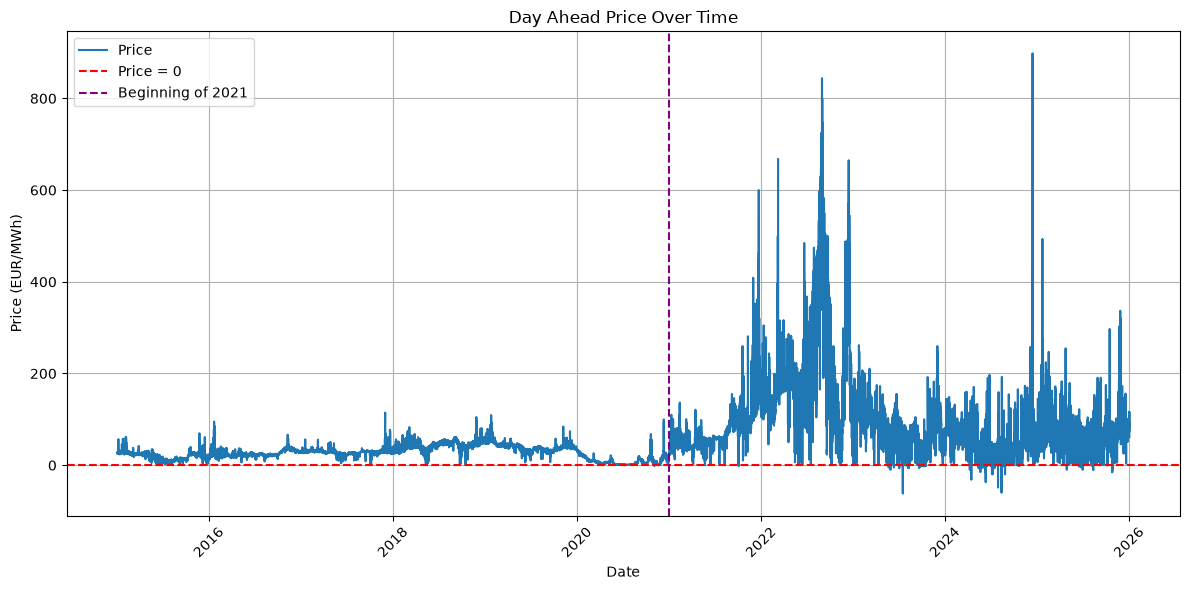

In [6]:
# plotting price over time
dap['date'] = pd.to_datetime(dap['date'], utc=True)
plt.figure(figsize=(12, 6))
sns.lineplot(x=dap['date'], y=dap['price'], label='Price')

# adding an orizotal line at y=0
plt.axhline(y=0, color='r', linestyle='--', label='Price = 0')

# adding a vertical line at the beginning of 2021
plt.axvline(x=pd.Timestamp('2021-01-01 00:00:00', tz='UTC'), color='purple', linestyle='--', label='Beginning of 2021')

# infos
plt.title('Day Ahead Price Over Time')
plt.xlabel('Date')
plt.ylabel('Price (EUR/MWh)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid()
plt.legend()
plt.show()

Until 2020 the price was low and smooth, whereas from 2021 onwards it became high, highly volatile. 
<br>
The main causes are:

Why it was calm before

- European energy crisis: Gas prices rose starting in 2021 and peaked with the invasion of Ukraine in 2022. 

- Low reservoirs: 2021–2022 was drier in southern Norway, and scarcer water holds a higher value, driving prices up.

<br>
Implications for the Model

- Distribution shift between train and test: The training set (2015–2022) contains five calm years and only two turbulent ones, while the test set (2023–2024) lies entirely within the volatile regime.

- Relative features: need to use features that do not depend on the absolute level—such as the price rank within the week, the price divided by the moving average, or the price relative to the water value.

In [7]:
# confirming that the price are given each hour of the day
#  and there a not mid indexed hours
df = dap.copy()
df['date'] = pd.to_datetime(df['date'], utc=True)
dt = df['date'].diff()
print(dt.groupby(df['date'].dt.year).value_counts().unstack(fill_value=0))  
# timestap with step < 1h 
print(df.loc[dt < pd.Timedelta('1h'), 'date'].min())                         
n = df.groupby(df['date'].dt.date).size()
print()
print(n.groupby(pd.to_datetime(n.index).year).agg(['min', 'max']))
print('24 = day, 96 = 15 min)')



date  0 days 00:15:00  0 days 01:00:00
date                                  
2015                0             8759
2016                0             8784
2017                0             8760
2018                0             8760
2019                0             8760
2020                0             8784
2021                0             8760
2022                0             8760
2023                0             8760
2024                0             8784
2025             8839             6551
2025-09-30 22:15:00+00:00

      min  max
date          
2015   24   24
2016   24   24
2017   24   24
2018   24   24
2019   24   24
2020   24   24
2021   24   24
2022   24   24
2023   24   24
2024   24   24
2025   24   96
24 = day, 96 = 15 min)


The data timestep is hourly, for eavery year form 2015 to 2024 (except 2025 which is out of range 
for this project)

Since it is a timeseries let's analyze the timeseries elements

      daily  weekly
date               
2015   0.26    0.17
2016   0.18    0.11
2017   0.17    0.10
2018   0.29    0.14
2019   0.25    0.17
2020   0.06    0.05
2021   0.08    0.08
2022   0.13    0.16
2023   0.12    0.13
2024   0.08    0.11
{1: np.float64(0.99), 24: np.float64(0.94), 48: np.float64(0.91), 168: np.float64(0.88)}


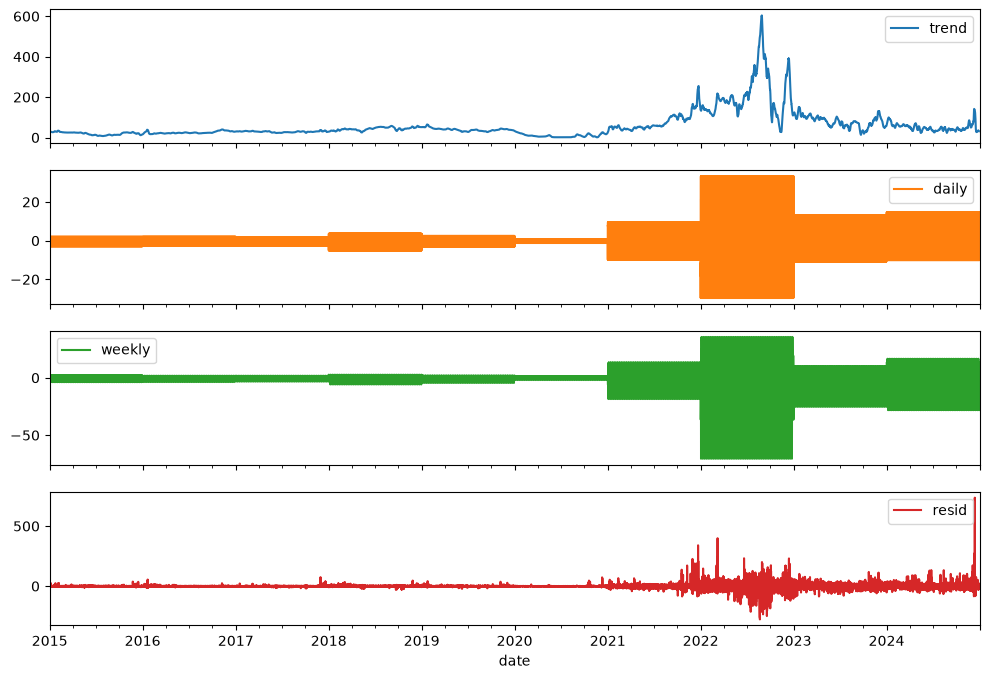

In [8]:
# keeping only the data before 2025, and setting the date as index 
df = dap[dap['date'] < '2025-01-01'].set_index('date')['price'].asfreq('h')

# computing the trend
trend = df.rolling(168, center=True).mean()          

# excluding the trrend
d = df - trend

# lables
#   hour
how = d.index.dayofweek * 24 + d.index.hour         
#   year
y = d.index.year

# computing the seasonal components
#   hourly, daily, weekly
s168 = d.groupby([y, how]).transform('mean')        
daily = d.groupby([y, d.index.hour]).transform('mean')
weekly = s168 - daily

# computing the residuals
resid = d - s168

# creating a dataframe with all the components and plotting them    
comp = pd.DataFrame({'trend': trend, 'daily': daily, 'weekly': weekly, 'resid': resid})
comp.plot(subplots=True, figsize=(12, 8))

# forza della stagionalità per anno: 1 - Var(resid) / Var(componente + resid)
ok = comp.dropna()
# computng the strength of the seasonal components for each year
f = lambda g, c: max(0, 1 - g['resid'].var() / (g[c] + g['resid']).var())
print(ok.groupby(ok.index.year).apply(lambda g: pd.Series({c: f(g, c) for c in ['daily', 'weekly']})).round(2))

# autocorrelation of the residuals
print({l: round(df.autocorr(l), 2) for l in (1, 24, 48, 168)})   

What We Can See:

- Trend: The level ranges between 20 and 60 EUR/MWh until 2020, then rises from 2021 and peaks at around 600 EUR/MWh.

- Daily Seasonality: The amplitude is within a few EUR until 2020 and grows starting in 2021, peaking in 2022 In 2023–2024, it remains higher than before 2021.

- Weekly Seasonality: Follows the same pattern but with a greater amplitude (the day-of-the-week signal carries more weight than the hour-of-the-day signal).

- Residuals: Extremely small until 2020 and then exploding, showing non-constant variance (heteroscedasticity) and periods of concentrated volatility.

<br>
Implications for the Model:

- Normalized features are needed

- The intra-weekly signal truly matters from 2021: If the AUC of price alone is high only from 2021 onwards, this confirms it.

- Better to use block cross-validation that includes the years 2021–2022, and compare training on the entire dataset versus training only on the recent period.

- Spikes: Hours with extreme prices (hundreds of EUR) can dominate any non-robust statistic: using the weekly rank is preferable as it is unaffected by amplitude.

### Inflow EDA

In [9]:
# Loading the inflow data
inflow = loader.inflow_data.copy()
inflow.head()

,date,Langesae,Staavatn,Kjelavatn,Bordalsvatn,Foersvatn,Hyljelihyl,Venemo,Bitdalsvatn,Songavatn,Totak,Vaamarvatn,Langeidvatn,Vatjern,Vinjevatn,Botnedalsvatn,Byrtevatn,Bandak,r_Vest_Vassdraget
0,1958-01-01 00:00:00+00:00,0.37,0.03,1.23,0.5,0.05,0.34,0.37,1.07,4.92,3.28,0.21,0.18,0.02,4.49,0.56,0.42,2.68,0.56
1,1958-01-01 01:00:00+00:00,0.37,0.03,1.23,0.5,0.05,0.34,0.37,1.07,4.92,3.28,0.21,0.18,0.02,4.49,0.56,0.42,2.68,0.56
2,1958-01-01 02:00:00+00:00,0.37,0.03,1.23,0.5,0.05,0.34,0.37,1.07,4.92,3.28,0.21,0.18,0.02,4.49,0.56,0.42,2.68,0.56
3,1958-01-01 03:00:00+00:00,0.37,0.03,1.23,0.5,0.05,0.34,0.37,1.07,4.92,3.28,0.21,0.18,0.02,4.49,0.56,0.42,2.68,0.56
4,1958-01-01 04:00:00+00:00,0.37,0.03,1.23,0.5,0.05,0.34,0.37,1.07,4.92,3.28,0.21,0.18,0.02,4.49,0.56,0.42,2.68,0.56


In [10]:
print('=== Inflow Data ========')
print(f'Shape: {inflow.shape}')
print(f'Columns: {inflow.columns}')
print(f'Null values: {inflow.isnull().sum().sum()}')
print(f'Duplicated values: {inflow.duplicated().sum()}')
print(f'statistics: {inflow.describe()}')
print('=========================')

=== Inflow Data ========
Shape: (594224, 19)
Columns: Index(['date', 'Langesae', 'Staavatn', 'Kjelavatn', 'Bordalsvatn', 'Foersvatn',
       'Hyljelihyl', 'Venemo', 'Bitdalsvatn', 'Songavatn', 'Totak',
       'Vaamarvatn', 'Langeidvatn', 'Vatjern', 'Vinjevatn', 'Botnedalsvatn',
       'Byrtevatn', 'Bandak', 'r_Vest_Vassdraget'],
      dtype='str')
Null values: 0
Duplicated values: 0
statistics:             Langesae       Staavatn      Kjelavatn    Bordalsvatn  \
count  594224.000000  594224.000000  594224.000000  594224.000000   
mean        1.791184       6.230031       3.205070       5.731122   
std         2.541559       9.061160       3.451059       9.967011   
min         0.000000       0.000000       0.000000       0.000000   
25%         0.270000       0.360000       0.760000       0.630000   
50%         0.800000       1.840000       1.690000       2.110000   
75%         2.130000       8.910000       4.600000       6.190000   
max        22.930000     102.430000      21.510000

Columns represent each one of the 17 reservoirs and the rows represent the inflow into each reservoir at each hour. Apart of r_Vest_Vassdrage which is a river

In [11]:
# transforming date column to datetime and setting it as index
inflow['date'] = pd.to_datetime(inflow['date'], utc=True)
inflow = inflow.set_index('date')

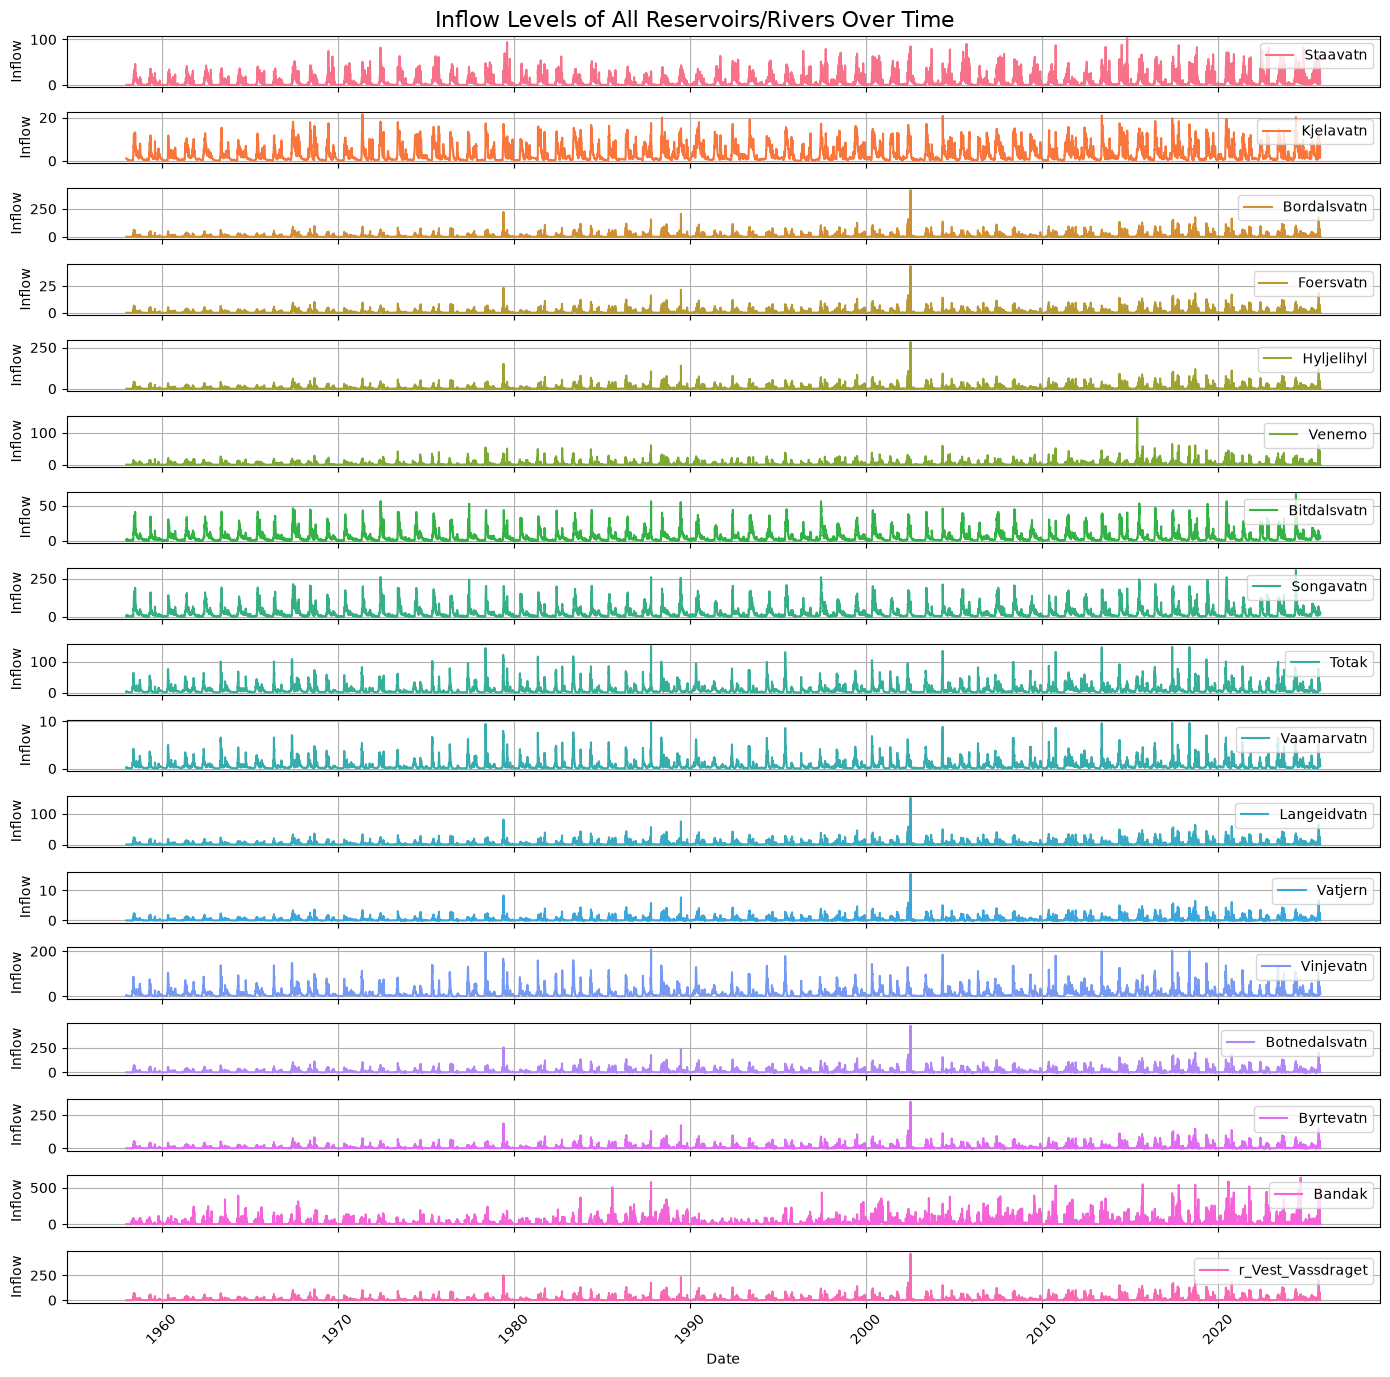

In [12]:
# plotting the distribution of inflow levels of each reservoir/river over time

fig, axes = plt.subplots(nrows=len(inflow.columns[1:]), ncols=1, figsize=(14, 14), sharex=True)

# generating a unique color for each line
colors = sns.color_palette("husl", len(inflow.columns[1:]))

for i, col in enumerate(inflow.columns[1:]):
    sns.lineplot(x=inflow.index, y=inflow[col], ax=axes[i], color=colors[i], label=col)
    axes[i].legend(loc='upper right')
    axes[i].grid(True)
    axes[i].set_ylabel('Inflow')

# infos
fig.suptitle('Inflow Levels of All Reservoirs/Rivers Over Time', fontsize=16)
plt.xlabel('Date')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

1. Time Interval

The file spans from January 1958 to approximately September 2025, while the labels range between 2015 and 2024. For training, only that target period is needed. 
<br>
But the historical data prior to 2015 can be used to compute the expected average inflow for each day of the year. From this can be deriverd which period is wetter or drier than usual.
<br>
2. Similar Series

There are three groups:
- Langesae, Kjelavatn, Bitdalsvatn, Songavatn, and partly Staavatn
- Totak, Vaamarvatn, and Vinjevatn
- Bordalsvatn, Foersvatn, Hyljelihyl, Langeidvatn, Vatjern, Botnedalsvatn, Byrtevatn, and r_Vest_Vassdraget, they look like the same series at different scales.

- Bandak and Venemo have a different profile.

Langesae              9004
Staavatn             13046
Kjelavatn            12476
Bordalsvatn          14471
Foersvatn            12303
Hyljelihyl           14259
Venemo               17046
Bitdalsvatn           9258
Songavatn             9311
Totak                13198
Vaamarvatn           11162
Langeidvatn          13809
Vatjern              10926
Vinjevatn            13227
Botnedalsvatn        14515
Byrtevatn            14363
Bandak               11467
r_Vest_Vassdraget    14515
dtype: int64


,Langesae,Staavatn,Kjelavatn,Bordalsvatn,Foersvatn,Hyljelihyl,Venemo,Bitdalsvatn,Songavatn,Totak,Vaamarvatn,Langeidvatn,Vatjern,Vinjevatn,Botnedalsvatn,Byrtevatn,Bandak,r_Vest_Vassdraget
date,,,,,,,,,,,,,,,,,,
2015,0.09,0.22,0.17,0.13,0.09,0.13,0.21,0.13,0.18,0.31,0.14,0.12,0.06,0.32,0.13,0.13,-0.22,0.13
2016,-0.02,0.13,-0.07,-0.17,-0.04,-0.14,0.12,-0.03,-0.03,0.07,0.02,-0.11,-0.01,0.07,-0.17,-0.16,-0.33,-0.17
2017,0.05,0.18,0.15,0.04,0.04,0.04,0.06,0.08,0.13,0.13,0.06,0.04,0.03,0.13,0.04,0.04,-0.24,0.04
2018,0.03,0.19,-0.06,-0.23,-0.03,-0.18,-0.15,0.04,0.05,-0.18,-0.02,-0.12,-0.01,-0.20,-0.24,-0.21,-0.73,-0.24
2019,-0.10,-0.01,-0.10,-0.35,-0.09,-0.30,-0.07,-0.14,-0.18,-0.01,0.01,-0.22,-0.04,-0.01,-0.37,-0.33,-0.22,-0.37
2020,0.03,0.27,0.21,0.03,0.04,0.03,0.22,0.02,-0.01,0.37,0.16,0.04,0.04,0.38,0.03,0.03,0.17,0.03
2021,-0.14,0.12,-0.15,-0.38,-0.10,-0.32,-0.18,-0.20,-0.25,-0.22,-0.06,-0.23,-0.04,-0.23,-0.40,-0.35,-0.38,-0.39
2022,-0.06,0.16,-0.06,-0.30,-0.07,-0.26,-0.17,-0.09,-0.10,-0.29,-0.07,-0.18,-0.03,-0.31,-0.32,-0.28,-0.63,-0.32
2023,0.00,0.12,-0.09,-0.20,-0.03,-0.16,0.04,-0.01,-0.02,0.09,0.07,-0.11,-0.00,0.08,-0.21,-0.18,-0.20,-0.21


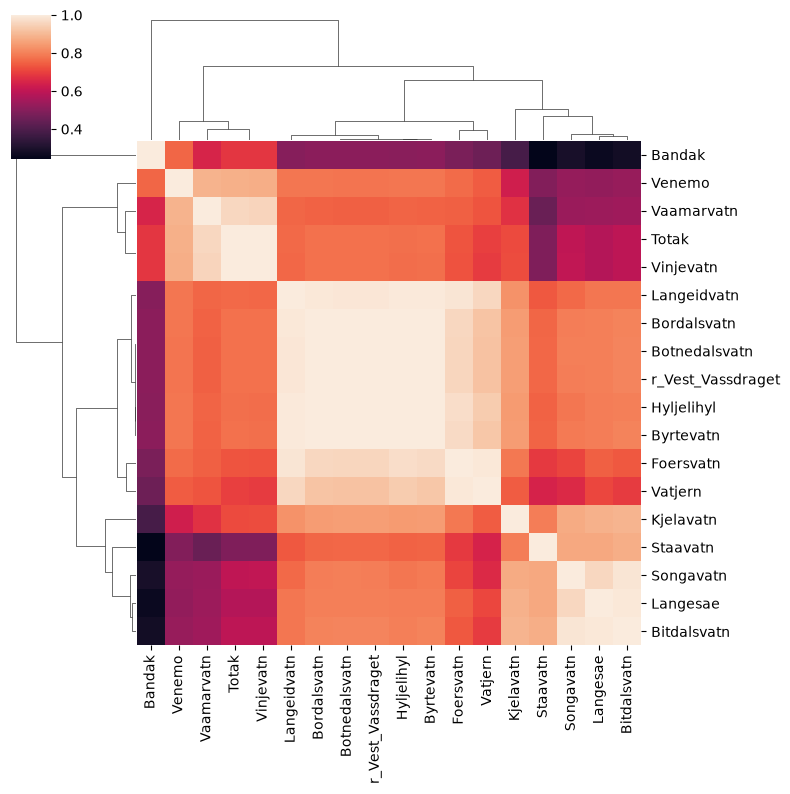

In [13]:
# testing some hypothesis

# does the value change during the day? (if yes, then the data is not daily)
print((inflow.groupby(inflow.index.date).nunique() > 1).sum())

# How similar are the seres? 
daily = inflow.resample('D').mean() # aggregating the data to daily frequency (using the daily mean)
sns.clustermap(np.log1p(daily).corr(), figsize=(8, 8))

# Climatology and anomalies
#   data before 2015 is used to compute the climatology, and data from 2015 to 2024 is used to compute the anomalies
pre = daily[:'2014']
clim = pre.groupby(pre.index.dayofyear).mean() # normal inflow
use = daily['2015':'2024']
anom_log = np.log1p(use) - np.log1p(clim.reindex(use.index.dayofyear).values)
anom_log.groupby(anom_log.index.year).mean().round(2) # >1 wet, 1< dry

Confirming the clusters: seven representative series are enough, one for each of groups A, B, and C, plus Kjelavatn, Staavatn, Venemo, and Bandak.

- Wet years: 2015, 2020, and 2024

- Dry years: 2019, 2021, and 2022. 

- Intermediate or mixed years: 2016, 2018, and 2023

The Link to the Price Chart

. The wet year 2020 is when prices crashed close to zero, whereas the dry 2021–2022 period marks the beginning of the price surge. Gas prices and European interconnectors explain the scale of the 2022 prices, but hydrology explains part of the direction. This suggests that the inflow (or volume) anomaly is a useful feature for understanding whether a period has abundant or scarce water.

date
1958    5.38
1980    4.30
2000    8.51
2014    8.65
2015    8.75
2024    8.43
Name: Staavatn, dtype: float64
      Langesae  Staavatn  Kjelavatn  Bordalsvatn  Foersvatn  Hyljelihyl  \
date                                                                      
1958      0.00      0.00       0.00         0.00       0.00        0.00   
1963      0.00      0.00       0.00         0.00       0.00        0.00   
1968      0.00      0.05       0.00         0.00       0.00        0.00   
1973      0.00      0.18       0.00         0.80       0.59        0.76   
1978      0.00      0.67       0.00         0.64       0.54        0.63   
1983      0.00      0.00       0.00         0.56       0.53        0.55   
1988      0.00      0.00       0.97         0.63       0.58        0.61   
1993      0.00      0.75       0.94         0.71       0.60        0.71   
1998      0.00      0.82       0.94         0.87       0.75        0.86   
2003      0.69      0.36       0.82         0.76       0.63  

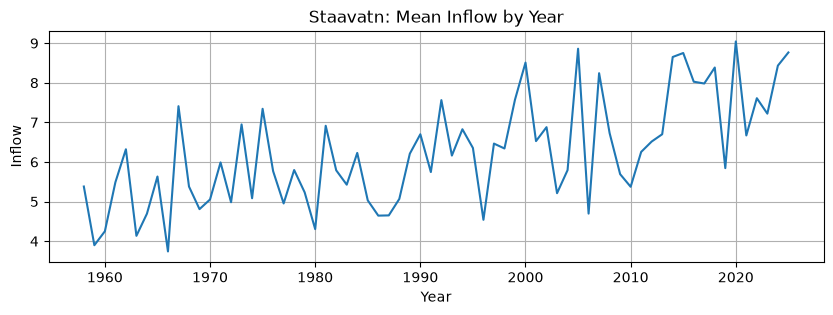

In [14]:
# Staavatn: there is a trend or a jump in the level?
y = daily['Staavatn'].groupby(daily.index.year).mean()
y.plot(figsize=(10, 3), grid=True)
print(y.loc[[1958, 1980, 2000, 2014, 2015, 2024]].round(2))
plt.title('Staavatn: Mean Inflow by Year')
plt.ylabel('Inflow')
plt.xlabel('Year')

# what fraction of days have intra-day variation, for each year
v = inflow.groupby(inflow.index.normalize()).nunique().gt(1)
print(v.groupby(v.index.year).mean().round(2).iloc[::5])

Staavant has a gradual trend

The share of days with intra-day variation changes significantly over time.
<br>
Up until several decades ago, the data consists of daily values repeated across 24 hours, and only recently has it become genuinely hourly. Aggregating to a daily level is the consistent choice for the entire dataset.

### Volume EDA

In [15]:
# loading the volume data
volume = loader.volume_data.copy()
volume.head()

,date,Kjelavatn,Staavatn,Langesae,Foersvatn,Venemo,Botnedalsvatn,Bitdalsvatn,Vaamarvatn,Langeidvatn,Totak,Songavatn,Vinjevatn,Bandak,Bordalsvatn,Byrtevatn,Hyljelihyl,Vatjern
0,2015-01-01 00:00:00+00:00,42.352,17.472,56.669,92.150,18.263,32.999,92.404,9.796,30.541,170.219,492.379,6.672,137.785,166.063,63.929,0.13,0.15
1,2015-01-02 00:00:00+00:00,42.001,16.474,56.262,92.185,18.332,32.999,92.024,11.079,30.587,170.219,489.891,5.959,137.785,165.969,63.884,0.13,0.15
2,2015-01-03 00:00:00+00:00,41.494,15.360,55.753,92.079,18.356,32.743,91.786,12.257,30.587,170.219,487.126,6.445,137.785,165.733,63.703,0.13,0.15
3,2015-01-04 00:00:00+00:00,41.221,14.784,55.516,91.938,18.388,32.589,91.453,11.425,30.541,169.512,485.468,6.996,137.785,165.591,63.568,0.13,0.15
4,2015-01-05 00:00:00+00:00,41.182,14.630,55.482,91.903,18.388,32.538,91.025,10.143,30.541,169.512,485.191,7.028,137.785,165.544,63.522,0.13,0.15


In [16]:
print('=== Volume Data ========')
print(f'Shape: {volume.shape}')
print(f'Columns: {volume.columns}')
print(f'Null values: {volume.isnull().sum().sum()}')
print(f'Duplicated values: {volume.duplicated().sum()}')
print(f'statistics: {volume.describe()}')
print('=========================')

=== Volume Data ========
Shape: (3654, 18)
Columns: Index(['date', 'Kjelavatn', 'Staavatn', 'Langesae', 'Foersvatn', 'Venemo',
       'Botnedalsvatn', 'Bitdalsvatn', 'Vaamarvatn', 'Langeidvatn', 'Totak',
       'Songavatn', 'Vinjevatn', 'Bandak', 'Bordalsvatn', 'Byrtevatn',
       'Hyljelihyl', 'Vatjern'],
      dtype='str')
Null values: 0
Duplicated values: 0
statistics:          Kjelavatn     Staavatn     Langesae    Foersvatn       Venemo  \
count  3654.000000  3654.000000  3654.000000  3654.000000  3654.000000   
mean     42.278923    27.197468    54.666674    71.503479    16.334140   
std      25.714729    20.541030    17.794533    33.618020     2.569264   
min       0.000000     0.384000    13.701000     0.425000     8.703000   
25%      16.099500     2.419000    43.273000    47.345000    14.454500   
50%      47.383000    34.982000    58.466000    82.188500    17.160000   
75%      63.988000    47.386000    69.420000    98.277250    18.294000   
max      86.979000    50.168000  

Water storage for each reservoir at the start of the day. Units: Million m3.

Columns represent each one of the 17 reservoirs. Note that because there are no historical records for two small reservoirs, Hyljelihyl and Vatjern, their storage is assumed to be 50% full.  

Notiche that:
* Significantly different scales: normalization must be performed on a reservoir-by-reservoir basis.
* Kjelavatn reaches 0. The minimum is 0.000: this could represent an empty reservoir or a missing value filled with zero. This needs to be verified.

In [17]:
# setting the date as index and converting it to datetime
volume = volume.set_index(pd.to_datetime(volume['date'], utc=True)).drop(columns='date')

In [18]:
print(volume.describe().T[['min', 'mean', 'max']].round(2))

# checking how many reservoirs have at least one day with zero volume
print((volume == 0).sum()[lambda s: s > 0])

# sesonality and variability of the volume data
print(volume.groupby(volume.index.month).mean().div(volume.max()).round(2))  
print(volume.diff().abs().mean().div(volume.std()).round(3)) 
# Last row shows how much the volume changes from one day to the next 
# compared to its overall variability: low values mean slow series, and then yesterday's 
# volume is a great predictor of today's.

                  min    mean     max
Kjelavatn        0.00   42.28   86.98
Staavatn         0.38   27.20   50.17
Langesae        13.70   54.67   78.62
Foersvatn        0.42   71.50  123.08
Venemo           8.70   16.33   21.81
Botnedalsvatn    0.40   32.28   55.78
Bitdalsvatn     14.87   78.44  111.82
Vaamarvatn       0.06   14.18   26.46
Langeidvatn      0.32   22.77   33.96
Totak            7.06  168.74  259.95
Songavatn       52.73  424.59  646.71
Vinjevatn        1.48    6.41   10.46
Bandak         103.83  132.48  206.05
Bordalsvatn      1.65  133.31  187.02
Byrtevatn        5.00   54.88   80.59
Hyljelihyl       0.13    0.13    0.13
Vatjern          0.15    0.15    0.15
Kjelavatn    1
dtype: int64
      Kjelavatn  Staavatn  Langesae  Foersvatn  Venemo  Botnedalsvatn  \
date                                                                    
1          0.53      0.15      0.61       0.69    0.76           0.59   
2          0.34      0.04      0.56       0.54    0.73           0.37

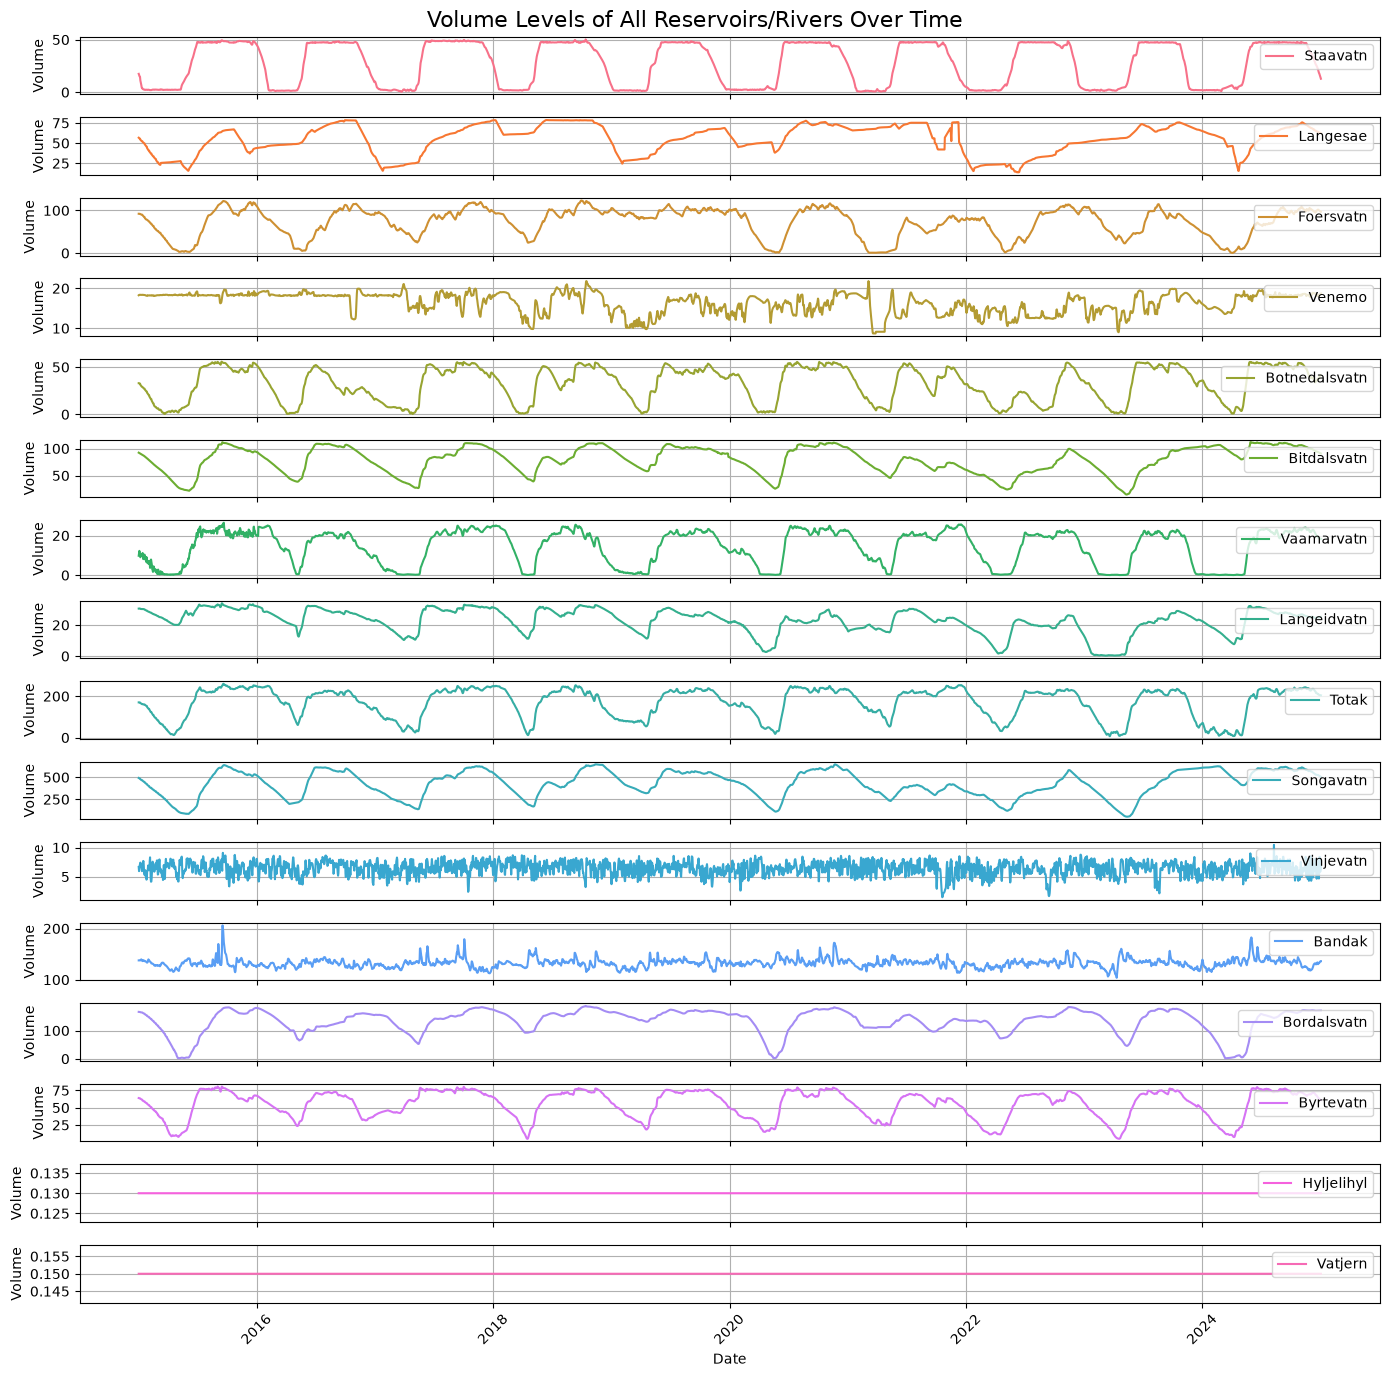

In [19]:
# plotting the distribution of valumes levels of each reservoir over time

fig, axes = plt.subplots(nrows=len(volume.columns[1:]), ncols=1, figsize=(14, 14), sharex=True)

# generating a unique color for each line
colors = sns.color_palette("husl", len(volume.columns[1:]))

for i, col in enumerate(volume.columns[1:]):
    sns.lineplot(x=volume.index, y=volume[col], ax=axes[i], color=colors[i], label=col)
    axes[i].legend(loc='upper right')
    axes[i].grid(True)
    axes[i].set_ylabel('Volume')

# infos
fig.suptitle('Volume Levels of All Reservoirs/Rivers Over Time', fontsize=16)
plt.xlabel('Date')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

The graph shows at least three type of reservoir
<br>
**Three Distinct Behaviors**

* Reservoirs with a strong annual cycle (Staavatn, Botnedalsvatn, Vaamarvatn, Bitdalsvatn, Langeidvatn, Totak, Songavatn, Bordalsvatn, Byrtevatn, Foersvatn): minimum in spring, maximum in late summer or autumn.
* Reservoirs without seasonality (Vinjevatn and Bandak): volume does not convey much seasonal information here, but it may provide insights into short-term dispatch/management.
* Venemo and Langesae (with anomalies): these are the two reservoirs that warrant closer inspection.

**Implications for Feature Engineering**

* Extremely slow-moving time series: tomorrow's volume is almost identical to today's, which means the level at `starttime` is sufficient and long lags are unnecessary.
* Relative rather than absolute levels: converting values into a filling fraction (`(v - min) / (max - min)`) makes reservoirs directly comparable. Values close to 1 indicate an impending risk of spillage and thus a strong operational incentive to generate power.
* Recent trend/variation: the difference between `volume[t]` and `volume[t-7]` indicates whether the reservoir is actively filling up or depleting.
* Seasonal positioning: The day of the year captures the annual cycle.
* Extreme water years: certain reservoirs drop very close to zero in the spring, the test set includes severe water scarcity periods.

In [20]:
# anomalies checks
# kjelavatn zero
print(volume['Kjelavatn'].idxmin(), volume['Kjelavatn'].min()) 

2020-04-20 00:00:00+00:00 0.0


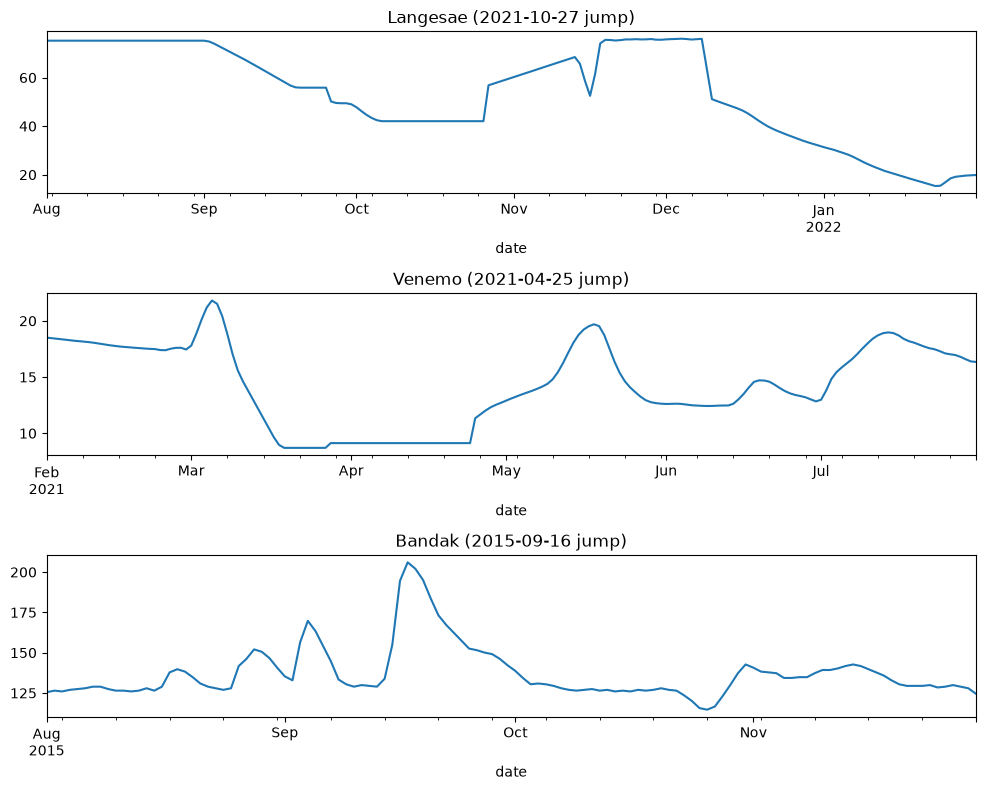

In [21]:
fig, ax = plt.subplots(3, 1, figsize=(10, 8))
volume['Langesae']['2021-08':'2022-01'].plot(ax=ax[0], title='Langesae (2021-10-27 jump)')
volume['Venemo']['2021-02':'2021-07'].plot(ax=ax[1], title='Venemo (2021-04-25 jump)')
volume['Bandak']['2015-08':'2015-11'].plot(ax=ax[2], title='Bandak (2015-09-16 jump)')
plt.tight_layout()

- Bandak (2015-09-16): Real Event, Keep As-Is: the pattern reflects the typical signature of an autumn flood.

- Langesae remains flat at around 42 throughout October, then on October 27 jumps in a single day to about 57 and continues to rise.

- Venemo stays flat at around 9 from mid-March to late April, followed by a sudden jump to roughly 11.5 on April 25.

A perfectly horizontal line lasting an entire month is uncharacteristic of a real water body, which typically fluctuates with inflows and discharges. The most plausible hypothesis is an observation gap filled via forward-filling, with the sudden step representing a return to true measurements.

In [22]:
# hypotesis test
v = volume.drop(columns=['Hyljelihyl', 'Vatjern'])
same = v.diff().abs().lt(1e-3)

run = same.apply(lambda s: s.groupby((~s).cumsum()).cumsum())   
end = run.idxmax()
print(pd.DataFrame({'max_run': run.max(), 'ends': end, 'level': [v[c][end[c]] for c in v]}))

               max_run                      ends    level
Kjelavatn            4 2017-02-15 00:00:00+00:00    3.828
Staavatn             5 2018-04-13 00:00:00+00:00    2.227
Langesae            47 2021-09-01 00:00:00+00:00   75.219
Foersvatn            3 2021-09-27 00:00:00+00:00   53.582
Venemo              27 2021-04-24 00:00:00+00:00    9.125
Botnedalsvatn        3 2019-09-12 00:00:00+00:00   42.906
Bitdalsvatn          6 2018-11-29 00:00:00+00:00  109.905
Vaamarvatn           4 2021-08-07 00:00:00+00:00   20.213
Langeidvatn         10 2023-03-28 00:00:00+00:00    0.550
Totak                4 2021-08-07 00:00:00+00:00  217.188
Songavatn            3 2017-11-24 00:00:00+00:00  620.372
Vinjevatn            2 2015-04-13 00:00:00+00:00    7.773
Bandak               5 2015-01-06 00:00:00+00:00  137.785
Bordalsvatn          6 2021-05-03 00:00:00+00:00  111.984
Byrtevatn            3 2019-09-13 00:00:00+00:00   73.910


In [23]:
print(run.where((run >= 14) & (run.shift(-1) == 0)).stack().dropna())

date                               
2021-04-24 00:00:00+00:00  Venemo      27.0
2021-09-01 00:00:00+00:00  Langesae    47.0
2021-10-26 00:00:00+00:00  Langesae    20.0
dtype: float64


**The Hypothesis**
The flat plateaus observed in the plots were presumed to be missing values imputed via forward-filling, with the sudden concluding jump marking a return to real measurements.

**What the Data Shows**
* Lack of widespread occurrence: if this were a systemic data quality issue, flat segments would appear frequently. Instead, just two time series.
* Physically plausible levels: two of the three segments sit at physically sensible thresholds.

**Limitation of the Check**
This check strictly searches for identical values within a tolerance of `1e-3`. A "pseudo-flat" period with tiny noise fluctuations would bypass this criterion; therefore, we cannot entirely rule out less rigid flat segments. However, visual inspection of the plots reveals no obvious candidates.

### Water value EDA

In [24]:
# loading water value data
wvalue = loader.synthetic_water_value_data.copy()
wvalue.head()

,date,Kjelavatn,Staavatn,Langesae,Foersvatn,Venemo,Botnedalsvatn,Bitdalsvatn,Vaamarvatn,Langeidvatn,Totak,Songavatn,Vinjevatn,Bandak,Bordalsvatn,Byrtevatn,Hyljelihyl,Vatjern
0,2015-01-01 00:00:00+00:00,40.49,40.49,31.81,31.81,28.98,38.70,30.13,28.98,4.78,28.98,30.13,22.65,7.73,31.81,9.32,28.98,4.78
1,2015-01-02 00:00:00+00:00,40.89,40.89,30.96,30.96,26.44,36.47,30.52,26.44,4.44,26.44,30.52,35.13,8.52,30.96,8.72,26.44,4.44
2,2015-01-03 00:00:00+00:00,40.87,40.87,30.51,30.51,26.36,36.35,30.39,26.36,4.28,26.36,30.39,35.30,10.18,30.51,8.43,26.36,4.28
3,2015-01-04 00:00:00+00:00,40.50,40.50,30.06,30.06,26.33,35.68,30.11,26.33,4.23,26.33,30.11,28.63,7.16,30.06,7.96,26.33,4.23
4,2015-01-05 00:00:00+00:00,39.51,39.51,29.35,29.35,26.06,34.59,29.58,26.06,3.89,26.06,29.58,31.33,3.14,29.35,7.40,26.06,3.89


In [25]:
print('=== Water value Data ========')
print(f'Shape: {wvalue.shape}')
print(f'Columns: {wvalue.columns}')
print(f'Null values: {wvalue.isnull().sum().sum()}')
print(f'Duplicated values: {wvalue.duplicated().sum()}')
print(f'statistics: {wvalue.describe()}')
print('=============================')

=== Water value Data ========
Shape: (3654, 18)
Columns: Index(['date', 'Kjelavatn', 'Staavatn', 'Langesae', 'Foersvatn', 'Venemo',
       'Botnedalsvatn', 'Bitdalsvatn', 'Vaamarvatn', 'Langeidvatn', 'Totak',
       'Songavatn', 'Vinjevatn', 'Bandak', 'Bordalsvatn', 'Byrtevatn',
       'Hyljelihyl', 'Vatjern'],
      dtype='str')
Null values: 0
Duplicated values: 0
statistics:          Kjelavatn     Staavatn     Langesae    Foersvatn       Venemo  \
count  3654.000000  3654.000000  3654.000000  3654.000000  3654.000000   
mean     67.012219    67.012219    64.202017    64.202017    67.103183   
std     119.086329   119.086329    93.985918    93.985918   110.906005   
min       0.010000     0.010000     0.010000     0.010000     0.010000   
25%      16.072500    16.072500    14.340000    14.340000    12.145000   
50%      34.905000    34.905000    33.135000    33.135000    34.135000   
75%      70.297500    70.297500    69.712500    69.712500    77.920000   
max    1202.570000  1202.570

Marginal water value for each reservoir at the start of the day. Unit: EUR/MWh. There are 17 
reservoirs.

In [26]:
wvalue = wvalue.set_index(pd.to_datetime(wvalue['date'], utc=True)).drop(columns='date')

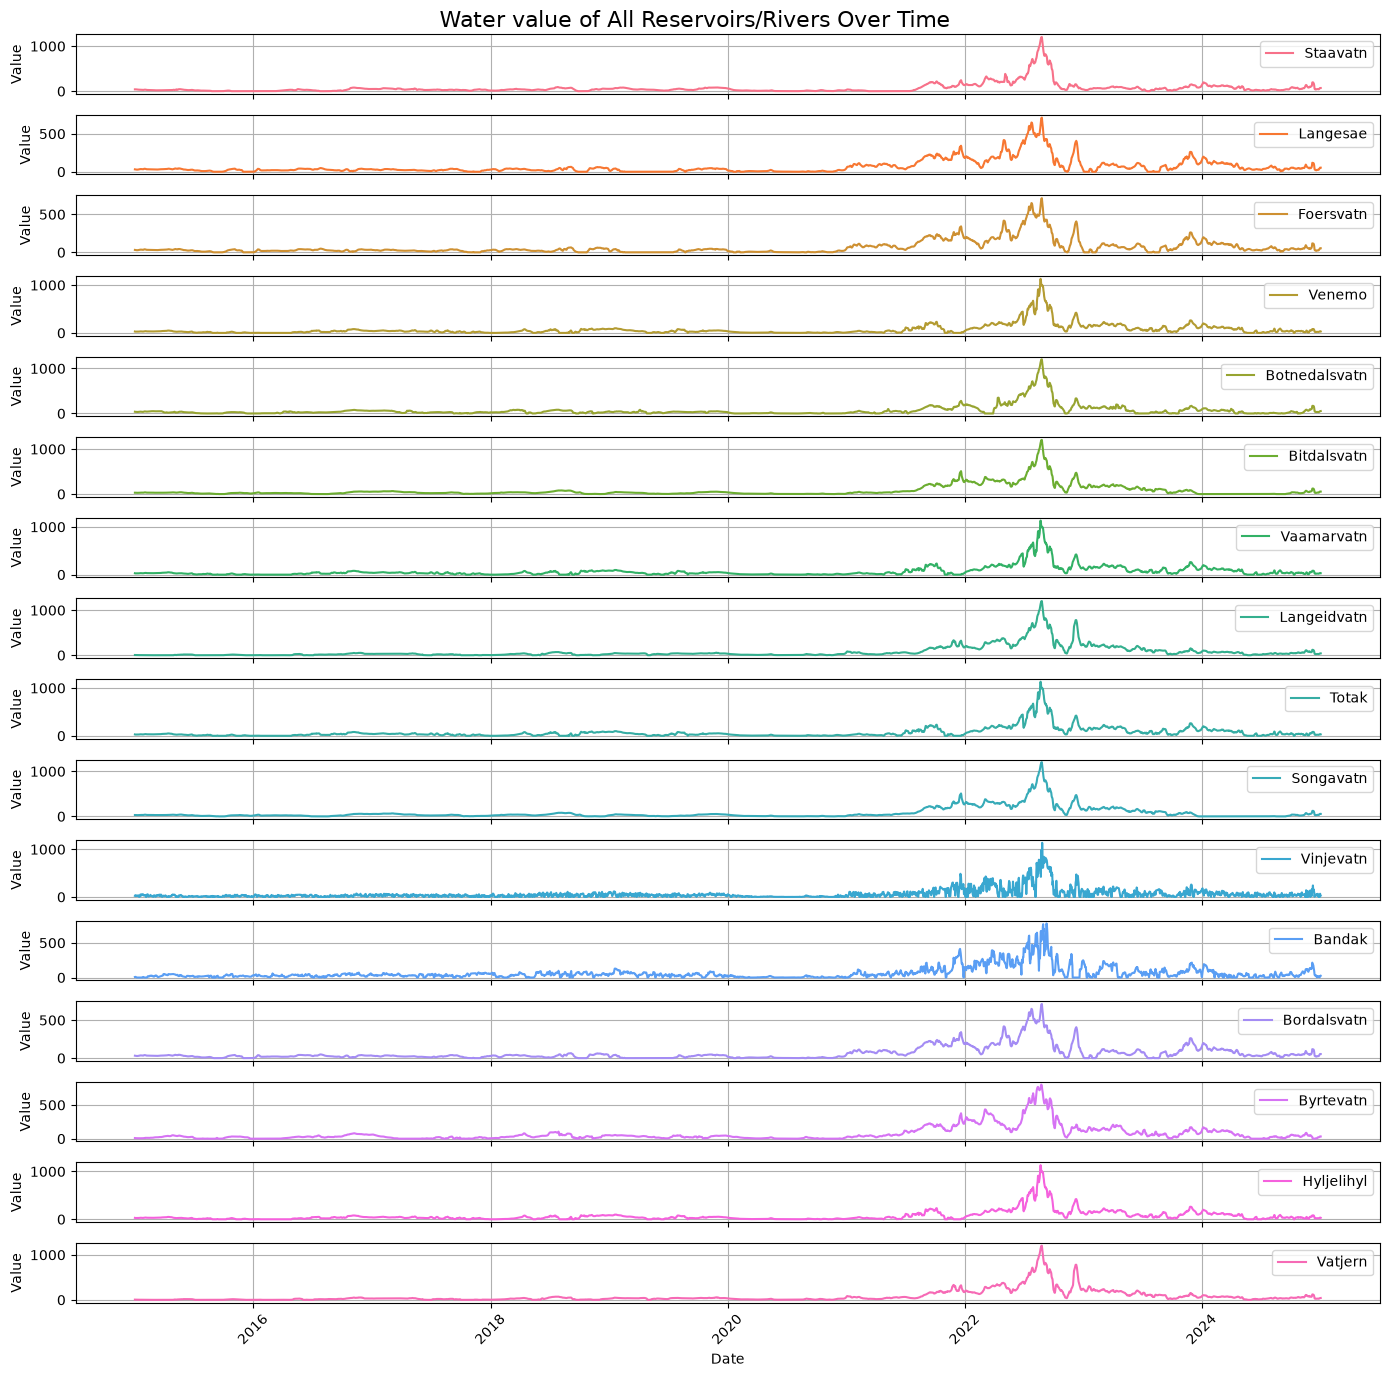

In [30]:
# plotting the series over time
fig, axes = plt.subplots(nrows=len(wvalue.columns[1:]), ncols=1, figsize=(14, 14), sharex=True)

# generating a unique color for each line
colors = sns.color_palette("husl", len(wvalue.columns[1:]))

for i, col in enumerate(wvalue.columns[1:]):
    sns.lineplot(x=wvalue.index, y=wvalue[col], ax=axes[i], color=colors[i], label=col)
    axes[i].legend(loc='upper right')
    axes[i].grid(True)
    axes[i].set_ylabel('Value')

# infos
fig.suptitle('Water value of All Reservoirs/Rivers Over Time', fontsize=16)
plt.xlabel('Date')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Water values are therefore likely assigned at the hydro-system level rather than on an individual reservoir basis.

* Highly skewed distribution: a handful of extreme days heavily pulls the mean upward.
* Floor at 0.01: this is likely an artificial lower bound applied when a reservoir is completely full or facing spillage risk
* Shared regime with power prices: it mirrors the underlying price trend, meaning the overall scale shifts by an order of magnitude across the years, as previously noted.

For a hydroelectric generator, the core economic rule is simple: generate power when the price exceeds the water value. The comparison between `price[h]` and `wv` is therefore the primary candidate for explaining unit commitment decisions.

In [39]:
# Daily mean price, aligned to the water value index
price = loader.day_ahead_price_data.copy()
price = price.set_index(pd.to_datetime(price['date'], utc=True)).drop(columns='date')
pm = price['Day-ahead price (EUR/MWh)'].resample('D').mean().reindex(wvalue.index)

# Reservoirs sharing the exact same water value series (rounded to 4 decimals)
h = wvalue.round(4).apply(lambda s: hash(tuple(s)))
print('=== Groups of reservoirs with identical water value series ===')
for i, g in enumerate(h.groupby(h).apply(lambda s: list(s.index)), 1):
    print(f'Group {i}: {g}')

=== Groups of reservoirs with identical water value series ===
Group 1: ['Byrtevatn']
Group 2: ['Venemo', 'Vaamarvatn', 'Totak', 'Hyljelihyl']
Group 3: ['Bandak']
Group 4: ['Bitdalsvatn', 'Songavatn']
Group 5: ['Vinjevatn']
Group 6: ['Botnedalsvatn']
Group 7: ['Kjelavatn', 'Staavatn']
Group 8: ['Langeidvatn', 'Vatjern']
Group 9: ['Langesae', 'Foersvatn', 'Bordalsvatn']


The 17 reservoirs collapse into 9 distinct water value series; reservoirs in the same group have exactly the same values.
One column per group is enough for the features.

In [41]:
# Share of days at the price floor (0.01), overall and per year
floor = wvalue <= 0.011
print('\n=== Share of days at the water value floor (<= 0.011), whole period ===')
print(floor.mean().round(3))



=== Share of days at the water value floor (<= 0.011), whole period ===
Kjelavatn        0.100
Staavatn         0.100
Langesae         0.100
Foersvatn        0.100
Venemo           0.102
Botnedalsvatn    0.101
Bitdalsvatn      0.076
Vaamarvatn       0.102
Langeidvatn      0.103
Totak            0.102
Songavatn        0.076
Vinjevatn        0.103
Bandak           0.103
Bordalsvatn      0.100
Byrtevatn        0.100
Hyljelihyl       0.102
Vatjern          0.103
dtype: float64


Almost every reservoir sits at the 0.01 floor on about 10% of days (7.6% for Bitdalsvatn and Songavatn).
The share is suspiciously uniform across groups, which may come from how the synthetic values were built.

In [42]:
print('\n=== Share of days at the water value floor, per year ===')
print(floor.groupby(floor.index.year).mean().round(2).T)


=== Share of days at the water value floor, per year ===
date           2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  \
Kjelavatn      0.27  0.27  0.00  0.08  0.00  0.00  0.36  0.00  0.02  0.00   
Staavatn       0.27  0.27  0.00  0.08  0.00  0.00  0.36  0.00  0.02  0.00   
Langesae       0.16  0.01  0.09  0.08  0.42  0.09  0.00  0.00  0.16  0.00   
Foersvatn      0.16  0.01  0.09  0.08  0.42  0.09  0.00  0.00  0.16  0.00   
Venemo         0.18  0.26  0.04  0.17  0.07  0.11  0.09  0.00  0.00  0.10   
Botnedalsvatn  0.17  0.05  0.02  0.06  0.04  0.28  0.04  0.09  0.11  0.14   
Bitdalsvatn    0.05  0.05  0.00  0.06  0.00  0.01  0.00  0.00  0.02  0.56   
Vaamarvatn     0.18  0.26  0.04  0.17  0.07  0.11  0.09  0.00  0.00  0.10   
Langeidvatn    0.51  0.17  0.19  0.11  0.02  0.00  0.00  0.00  0.00  0.03   
Totak          0.18  0.26  0.04  0.17  0.07  0.11  0.09  0.00  0.00  0.10   
Songavatn      0.05  0.05  0.00  0.06  0.00  0.01  0.00  0.00  0.02  0.56   
Vinjevatn      0.1

Floor days are not tied to a specific year: they cluster in different years for each group (e.g. Kjelavatn/Staavatn in 2015-16 and 2021, Bitdalsvatn/Songavatn in 2024).
So the floor is not driven by price; a full-reservoir effect is a hypothesis still to be checked.

In [43]:
# Spearman correlation between each water value and the daily mean price
print('\n=== Spearman correlation: water value vs daily mean day-ahead price ===')
print(wvalue.corrwith(pm, method='spearman').round(2))


=== Spearman correlation: water value vs daily mean day-ahead price ===
Kjelavatn        0.73
Staavatn         0.73
Langesae         0.69
Foersvatn        0.69
Venemo           0.71
Botnedalsvatn    0.67
Bitdalsvatn      0.66
Vaamarvatn       0.71
Langeidvatn      0.82
Totak            0.71
Songavatn        0.66
Vinjevatn        0.61
Bandak           0.68
Bordalsvatn      0.69
Byrtevatn        0.80
Hyljelihyl       0.71
Vatjern          0.82
dtype: float64


Water values correlate with the daily mean price (Spearman 0.61 to 0.82), partly because both rise together in 2021-22.
The hourly gap between price and water value is what may add information beyond the price alone.

In [44]:
# One representative reservoir per water value group
reps = ['Byrtevatn', 'Venemo', 'Bandak', 'Bitdalsvatn', 'Vinjevatn',
        'Botnedalsvatn', 'Kjelavatn', 'Langeidvatn', 'Langesae']

# Fill level (0-1) of each reservoir, on floor days vs the other days
fill = (volume - volume.min()) / (volume.max() - volume.min())
print('=== Mean fill level on water value floor days vs other days ===')
print(pd.DataFrame({'floor_days': fill[reps][floor[reps]].mean(),
                    'other_days': fill[reps][~floor[reps]].mean()}).round(2))

# Spearman correlation with the daily mean price, year by year
print('\n=== Spearman correlation water value vs daily price, per year ===')
yearly = wvalue[reps].groupby(wvalue.index.year).apply(lambda g: g.corrwith(pm[g.index], method='spearman'))
print(yearly.round(2).T)

=== Mean fill level on water value floor days vs other days ===
               floor_days  other_days
Byrtevatn            0.85        0.64
Venemo               0.67        0.57
Bandak               0.42        0.26
Bitdalsvatn          0.90        0.64
Vinjevatn            0.72        0.53
Botnedalsvatn        0.77        0.55
Kjelavatn            0.84        0.45
Langeidvatn          0.88        0.64
Langesae             0.59        0.64

=== Spearman correlation water value vs daily price, per year ===
date           2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  \
Byrtevatn      0.43  0.72  0.39  0.50  0.69  0.54  0.87  0.59  0.76  0.49   
Venemo         0.58  0.70  0.18  0.34  0.61  0.77  0.23  0.81  0.74  0.51   
Bandak         0.11  0.46  0.33  0.19  0.53  0.52  0.70  0.44  0.34  0.39   
Bitdalsvatn    0.69  0.52  0.40  0.30  0.49  0.78  0.90  0.84  0.63 -0.19   
Vinjevatn      0.47  0.27 -0.02  0.14  0.28  0.65  0.49  0.55  0.28  0.38   
Botnedalsvatn  0.75  0.62  

In 8 of 9 water value groups, floor days coincide with fuller reservoirs; Langesae is the exception.
The mean never reaches 1, so the floor is associated with high storage but is not simply "full reservoir"; a floor indicator is still worth testing as a feature.

Within each year the correlation between water value and daily price is much lower and unstable, so the overall 0.6-0.8 is inflated by the 2021-22 regime change.
Years with many floor days tend to have low correlation, so water value carries information that price alone does not. 

<br>
Notice that the 2025 column is NaN because it contains a single day.